<center><h1>Last_First_HW4</h1></center>
<br>
<br>

Name: Mario Prado
<br>
Github Username: mrpradooo
<br>
USC ID: 4223775338

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import os, re, warnings
import numpy as np
import seaborn as sns
import statsmodels.api as sm
import pandas as pd
import matplotlib.pyplot as plt


from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score,
                             accuracy_score, auc)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.feature_selection import RFE
from sklearn.preprocessing import StandardScaler, MinMaxScaler, label_binarize

warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
SEED = 552


Get the AReM Data Set

In [ ]:
ACTIVITIES = ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']
SERIES = ['avg_rss12', 'var_rss12', 'avg_rss13', 'var_rss13', 'avg_rss23', 'var_rss23']
BASE_PATH = '../data/AReM/'

def numeric_sort_key(filename):
    return int(re.search(r'\d+', filename).group())

def read_sensor_file(file_path):
    rows = []
    with open(file_path) as f:
        for line in f:
            if line.startswith('#') or not line.strip():
                continue
            parts = [p for p in re.split(r'[,\s]+', line.strip()) if p]   
            if len(parts) >= 7:
                rows.append([float(x) for x in parts[:7]])
    return pd.DataFrame(rows, columns=['time'] + SERIES)

### (b) Splitting Data

In [ ]:
def load_instances(base_path):
    train, test = [], []
    for activity in ACTIVITIES:
        folder = os.path.join(base_path, activity)
        files = sorted([f for f in os.listdir(folder) if f.endswith('.csv')], key=numeric_sort_key)
        n_test = 2 if activity.startswith('bending') else 3
        for i, f in enumerate(files):
            arr = read_sensor_file(os.path.join(folder, f))[SERIES].values
            (test if i < n_test else train).append((activity, f, arr))
    return train, test

train_inst, test_inst = load_instances(BASE_PATH)
print(f'train: {len(train_inst)} instances, test: {len(test_inst)} instances')
print('test files:', sorted(f'{a}/{f}' for a, f, _ in test_inst))

train: 69 instances, test: 19 instances
test files: ['bending1/dataset1.csv', 'bending1/dataset2.csv', 'bending2/dataset1.csv', 'bending2/dataset2.csv', 'cycling/dataset1.csv', 'cycling/dataset2.csv', 'cycling/dataset3.csv', 'lying/dataset1.csv', 'lying/dataset2.csv', 'lying/dataset3.csv', 'sitting/dataset1.csv', 'sitting/dataset2.csv', 'sitting/dataset3.csv', 'standing/dataset1.csv', 'standing/dataset2.csv', 'standing/dataset3.csv', 'walking/dataset1.csv', 'walking/dataset2.csv', 'walking/dataset3.csv']


### (c) Feature Extraction

In [ ]:
STAT_FUNCS = {'min': np.min, 'max': np.max, 'mean': np.mean, 'median': np.median,
              'std': lambda x: np.std(x, ddof=1),
              '1st_quart': lambda x: np.quantile(x, 0.25), '3rd_quart': lambda x: np.quantile(x, 0.75)}

def extract_features(instances, l=1, stats=('min', 'mean', 'max'), series=range(1, 7)):
    rows, labels = [], []
    for activity, _, arr in instances:
        feats = {}
        for s in series:
            for p, seg in enumerate(np.array_split(arr[:, s - 1], l), start=1):
                for st in stats:
                    feats[f'{st}{s}' if l == 1 else f'{st}{s}_p{p}'] = STAT_FUNCS[st](seg)
        rows.append(feats)
        labels.append(activity)
    return pd.DataFrame(rows), np.array(labels)

is_bending = lambda labels: np.isin(labels, ['bending1', 'bending2']).astype(int)

X1, lab1 = extract_features(train_inst, l=1)
print(X1.shape)
print(pd.Series(lab1).value_counts().to_string())

(69, 18)
cycling     12
sitting     12
lying       12
standing    12
walking     12
bending1     5
bending2     4


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

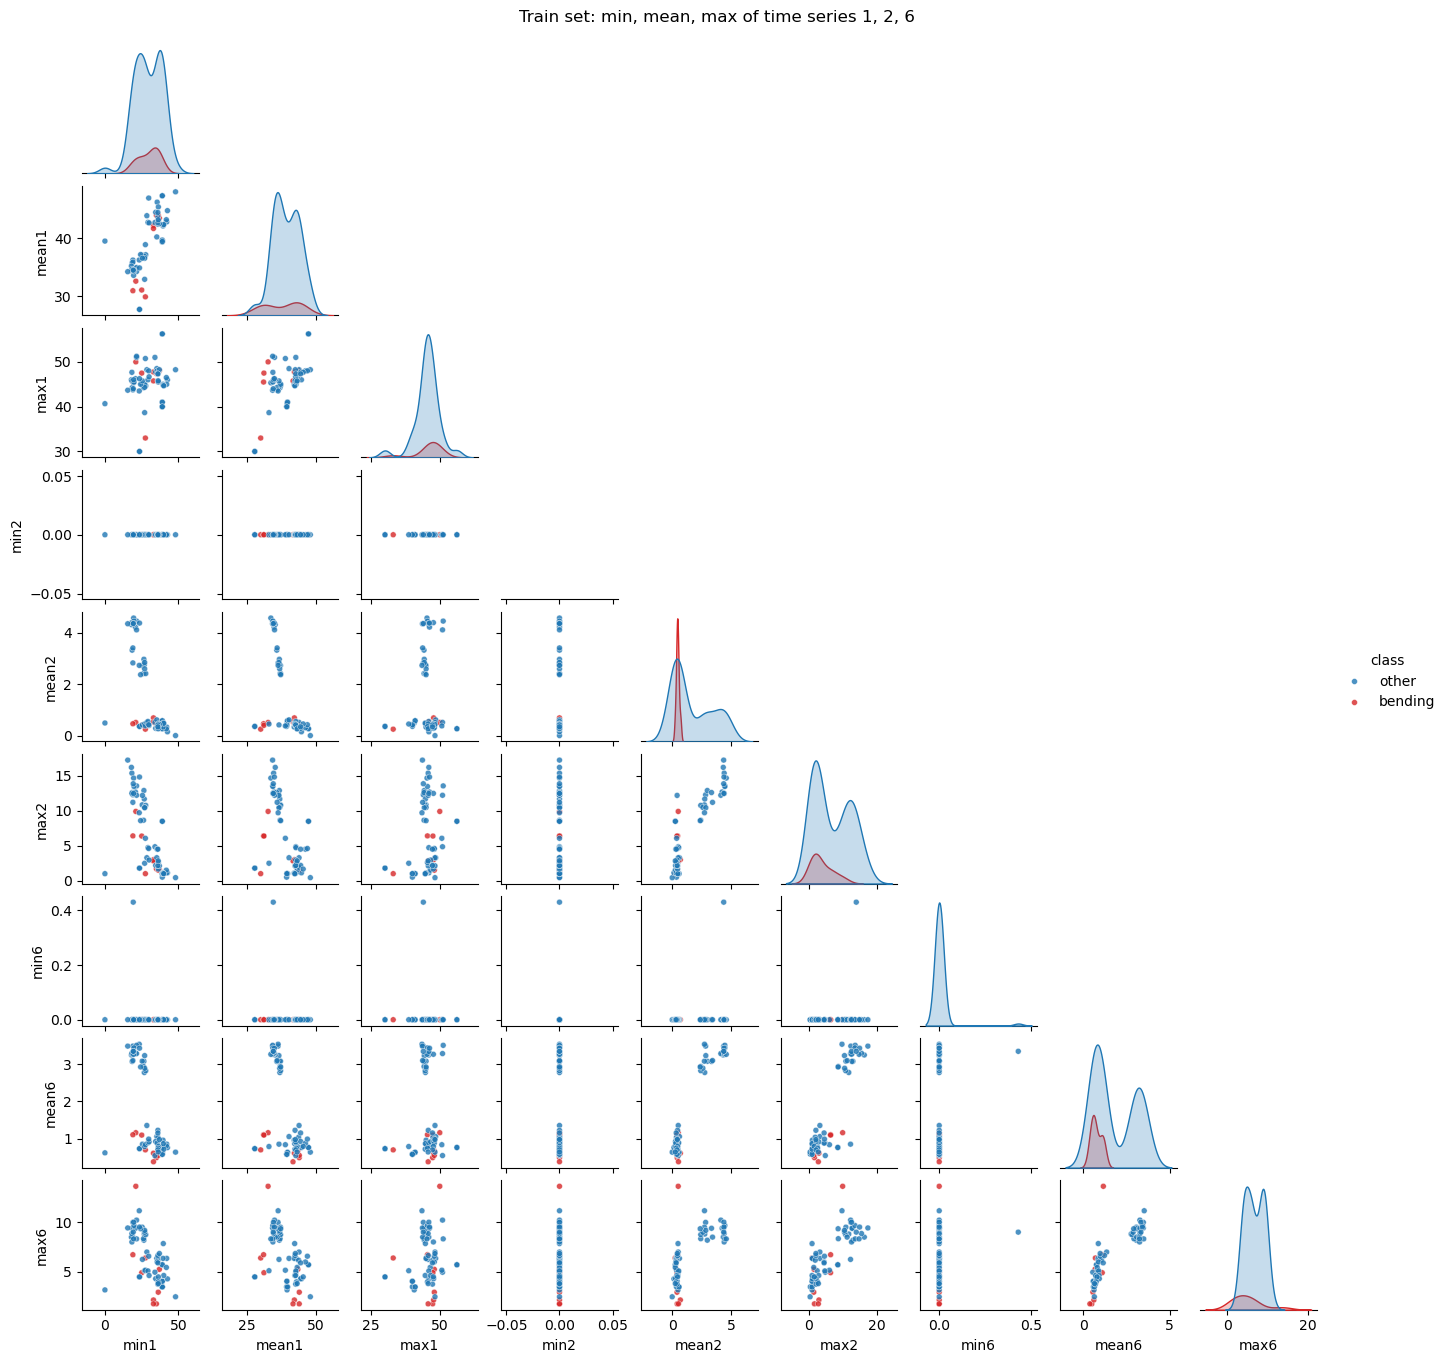

In [6]:
Ans, env = extract_features(train_inst, l=1, series=[1, 2, 6])
Ans['class'] = np.where(is_bending(env) == 1, 'bending', 'other')
g = sns.pairplot(Ans, hue='class', hue_order=['other', 'bending'], palette={'bending': 'tab:red', 'other': 'tab:blue'},
                 height=1.5, plot_kws={'s': 18, 'alpha': .8}, corner=True)
g.fig.suptitle('Train set: min, mean, max of time series 1, 2, 6', y=1.01)
plt.show()

#### ii. Splitted Plots

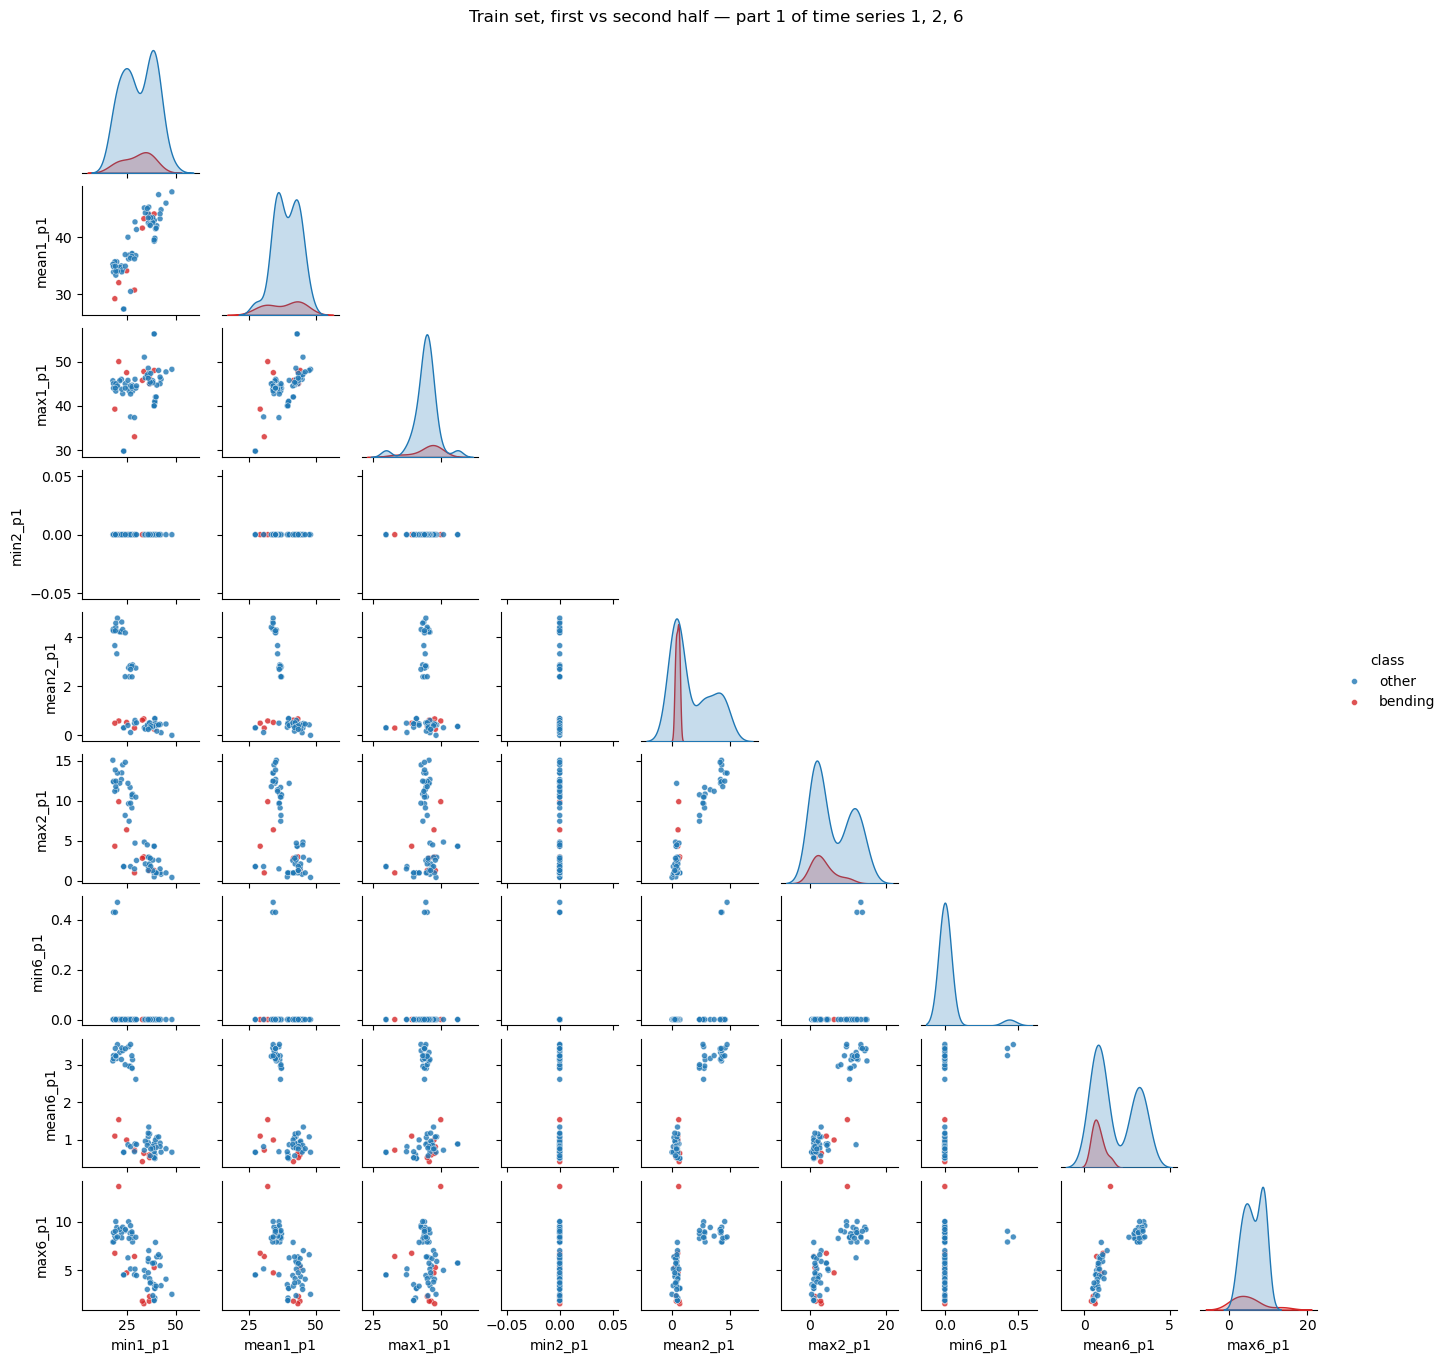

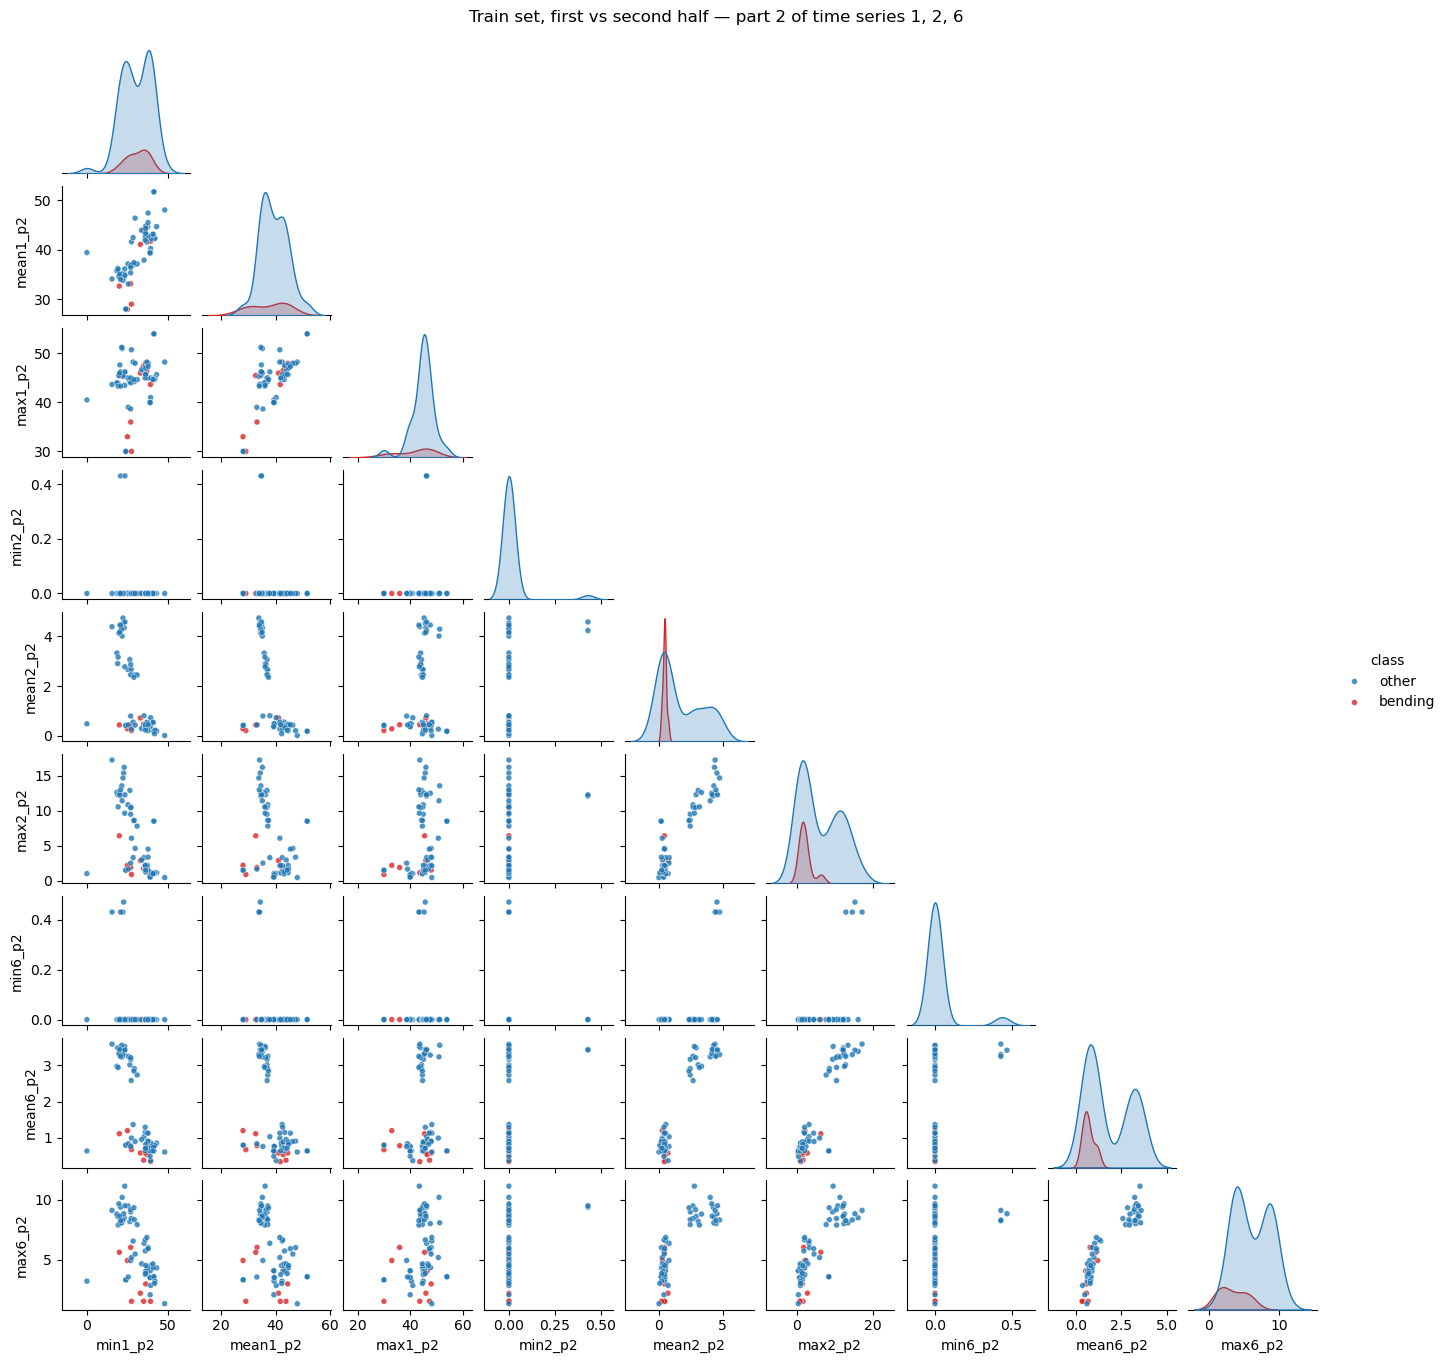

In [8]:
Ans_dos, env_dos = extract_features(train_inst, l=2, series=[1, 2, 6])
cls = np.where(is_bending(env_dos) == 1, 'bending', 'other')
for part in (1, 2):
    dataf = Ans_dos[[c for c in Ans_dos.columns if c.endswith(f'_p{part}')]].copy()
    dataf['class'] = cls
    h= sns.pairplot(dataf, hue='class', hue_order=['other', 'bending'],
                     palette={'bending': 'tab:red', 'other': 'tab:blue'},
                     height=1.5, plot_kws={'s': 18, 'alpha': .8}, corner=True)
    h.fig.suptitle(f'Train set, first vs second half — part {part} of time series 1, 2, 6', y=1.01)
    plt.show()

There appears to be no significant or considerable difference between the results here and those from 2(a)i. For every half and it's scatter plot, it look nearly the same as the l = 1 plot. We still see bending overlap with a zone of low-variance "other" isntaces in all the 2-D plots. Also because each is event pretty steady across the 2-mins, we can say these min/mean/max of each half are a good estimate of what they could be the whole series. Splitting can be uself as we see it doubels the number of features so if we ever need that but in reality it doesn't help us much when it comes to gaining more info on separating.

#### iii. Time Series Segments

Okay so when it comes to this problem there's a right way and a wrong way to doing cross-validation. The wrong way is when you do the p-value pruning only once on the entire training set and follow that up with cross-validating a logistic regression on the features it chose. The reason this is bad is our CV accuracy is now skewed due to the held-out folds already having an effect on our chosen features. And the accruacy is skewed towards a more optimistic bias something that would be pretty bad in our case since we have so many candidates so we're bound to have features that separate classes by chance.

I decided to go with stratified folds because if you look at the data you'll notice bending is only in 9 of the total 69 training instances. This way each class will keep the proper overall proportions which have bending at about 13%. This way I make sure there's not a single time without a bending instance. This five fold split is repeated 3 timse to ensure there are no more mistakes as they could prove quite costly. One mistake coudl even move our accuracy by 7 whole points.

I also went ahead and capped the max number of iterations as the instructions had recomended. 

In [ ]:
LR_UNPENALIZED = lambda: LogisticRegression(C=1e10, max_iter=100)
P_MAXIMUM = 20


def rec_feat_elim_ranking(Xtr, ytr, p_max=P_MAXIMUM):
    keep = np.arange(Xtr.shape[1])
    if Xtr.shape[1] > p_max:
        keep = np.where(RFE(LR_UNPENALIZED(), n_features_to_select=p_max, step=0.1).fit(Xtr, ytr).support_)[0]
    rank = RFE(LR_UNPENALIZED(), n_features_to_select=1, step=1).fit(Xtr[:, keep], ytr).ranking_
    return keep, rank

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rows = []
for l in range(1, 21):
    Xl, lab = extract_features(train_inst, l)
    Xl, y = Xl.values, is_bending(lab)
    P = min(Xl.shape[1], P_MAXIMUM)
    acc = np.zeros(P)
    for tr, va in cv.split(Xl, y):
        sc = StandardScaler().fit(Xl[tr])                 
        Xtr, Xva = sc.transform(Xl[tr]), sc.transform(Xl[va])
        keep, rank = rec_feat_elim_ranking(Xtr, y[tr])              
        for p in range(1, P + 1):
            cols = keep[rank <= p]
            m = LR_UNPENALIZED().fit(Xtr[:, cols], y[tr])
            acc[p - 1] += accuracy_score(y[va], m.predict(Xva[:, cols])) / cv.get_n_splits()
    rows += [dict(l=l, n_features=Xl.shape[1], p=p, cv_acc=acc[p - 1]) for p in range(1, P + 1)]

cv_rfe = pd.DataFrame(rows)
best = cv_rfe.sort_values(['cv_acc', 'p', 'l'], ascending=[False, True, True]).iloc[0]
L_BEST, P_BEST, CV_ACC_REC_FEAT_ELIM = int(best.l), int(best.p), best.cv_acc
print(cv_rfe.sort_values(['cv_acc', 'p', 'l'], ascending=[False, True, True]).head(10).to_string(index=False))
print(f'\nBest: l = {L_BEST}, p = {P_BEST}, CV accuracy = {CV_ACC_REC_FEAT_ELIM:.4f}')

 l  n_features  p   cv_acc
 1          18 10 0.990476
 1          18 11 0.985714
 1          18  9 0.980952
 1          18 12 0.980952
 1          18 13 0.980952
 1          18 15 0.980952
 1          18 16 0.980952
 1          18 17 0.980952
 1          18 18 0.980952
 1          18 14 0.976190

Best: l = 1, p = 10, CV accuracy = 0.9905


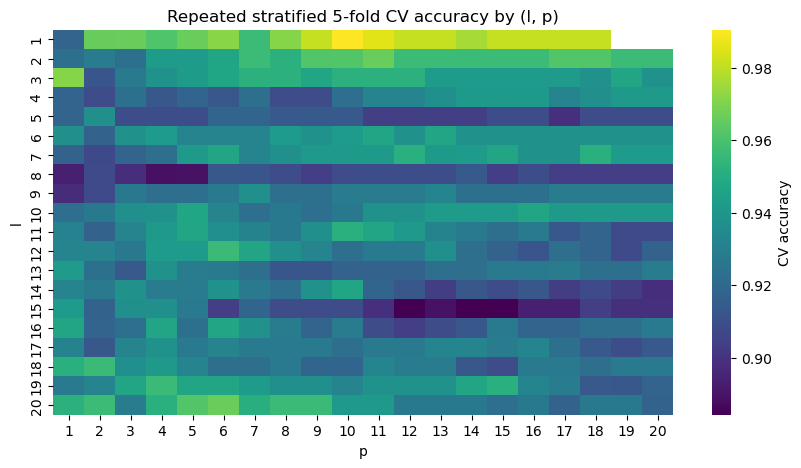

In [10]:
key = cv_rfe.pivot(index='l', columns='p', values='cv_acc')
plt.figure(figsize=(10, 5))
sns.heatmap(key, cmap='viridis', annot=False, cbar_kws={'label': 'CV accuracy'})
plt.title('Repeated stratified 5-fold CV accuracy by (l, p)')
plt.show()

We see from our results that the best pair is for sure l = 1 and p = 10. With this combo we get a consistent CV accuracy of around 0.990. From this we learn that a larger l isn't a good thing due to the fact that more pieces means more featues and when we only have 69 instances these just cause more nosie and lower accuracy.

#### iv. Confusion Matrix

Selected features: ['min1', 'mean1', 'max2', 'min3', 'mean3', 'mean4', 'max4', 'min5', 'mean5', 'max5']


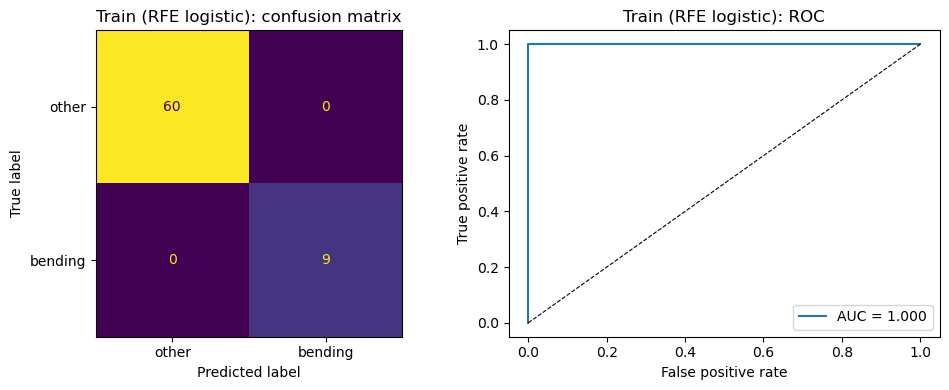

Train (RFE logistic): accuracy = 1.0000, AUC = 1.0000


(1.0, 1.0)

In [15]:
Xtrain_df, lab_tr = extract_features(train_inst, L_BEST)
Xtest_df, lab_te = extract_features(test_inst, L_BEST)       
ytrain, ytest = is_bending(lab_tr), is_bending(lab_te)

scaler = StandardScaler().fit(Xtrain_df.values)
Ztrain, Ztest = scaler.transform(Xtrain_df.values), scaler.transform(Xtest_df.values)
keep, rank = rec_feat_elim_ranking(Ztrain, ytrain)
selected_idx = keep[rank <= P_BEST]
selected_names = list(Xtrain_df.columns[selected_idx])
print('Selected features:', selected_names)

lr_rfe = LR_UNPENALIZED().fit(Ztrain[:, selected_idx], ytrain)
p_train = lr_rfe.predict_proba(Ztrain[:, selected_idx])[:, 1]

def show_confusion_matrix_roc(y, prob, title, pred=None):
    pred = (prob >= 0.5).astype(int) if pred is None else pred
    fig, ax = plt.subplots(1, 2, figsize=(10, 4))
    ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=['other', 'bending']).plot(ax=ax[0], colorbar=False)
    ax[0].set_title(f'{title}: confusion matrix')
    fpr, tpr, _ = roc_curve(y, prob)
    a = roc_auc_score(y, prob)
    ax[1].plot(fpr, tpr, label=f'AUC = {a:.3f}'); ax[1].plot([0, 1], [0, 1], 'k--', lw=.8)
    ax[1].set(xlabel='False positive rate', ylabel='True positive rate', title=f'{title}: ROC'); ax[1].legend()
    plt.tight_layout(); plt.show()
    print(f'{title}: accuracy = {accuracy_score(y, pred):.4f}, AUC = {a:.4f}')
    return accuracy_score(y, pred), a

show_confusion_matrix_roc(ytrain, p_train, 'Train (RFE logistic)')

In [13]:

exog = sm.add_constant(pd.DataFrame(Ztrain[:, selected_idx], columns=selected_names))

for it in [100, 50, 35, 25, 15, 10]:
    try:
        stat_model_fit = sm.Logit(ytrain, exog).fit(disp=0, maxiter=it, warn_convergence=False)
        break
    except np.linalg.LinAlgError:
        continue
print('iterations allowed:', it)

coefficient_table = pd.DataFrame({'beta (statsmodels)': stat_model_fit.params, 'std err': stat_model_fit.bse, 'p-value': stat_model_fit.pvalues,
                           'beta (sklearn)': np.r_[lr_rfe.intercept_, lr_rfe.coef_.ravel()]})
print('converged:', stat_model_fit.mle_retvals.get('converged'))
coefficient_table

iterations allowed: 50
converged: False


,beta (statsmodels),std err,p-value,beta (sklearn)
const,-49.501623,4.333030e+07,0.999999,-10.580322
min1,-3.361651,9.480219e+07,1.000000,-2.268706
mean1,-9.041043,1.902806e+07,1.000000,-1.416879
max2,-25.339693,9.322822e+07,1.000000,-2.773196
min3,-1.374667,8.617554e+07,1.000000,-1.546586
mean3,-6.561451,7.318029e+07,1.000000,-2.271172
mean4,-11.527534,2.527906e+08,1.000000,-1.977255
max4,19.824748,1.580028e+08,1.000000,1.782041
min5,26.714199,8.553609e+07,1.000000,4.589790
mean5,-4.697184,1.096268e+08,1.000000,2.531383


So when we refit with l = 1 and RFE on the entire training set these are the 10 features we get. When it comes to the training data we get a perfect accuracy as the classifier is perfect in all instances.

When it comes to the p-values we see that all of them are exactly 1 or around 1. We notice that the fit didn't converge but this doesn't automatiaclly mean our features are useles..

#### v. Test Classifier

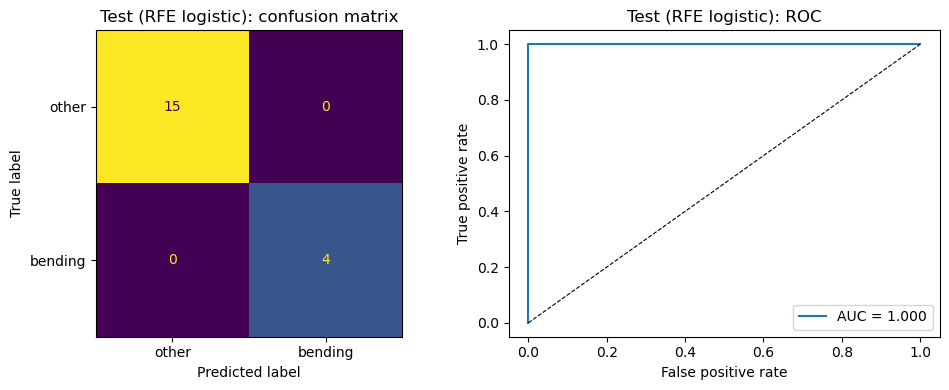

Test (RFE logistic): accuracy = 1.0000, AUC = 1.0000
CV accuracy = 0.9905  vs  test accuracy = 1.0000


In [16]:
p_test = lr_rfe.predict_proba(Ztest[:, selected_idx])[:, 1]
TEST_ACC_RFE, TEST_AUC_RFE = show_confusion_matrix_roc(ytest, p_test, 'Test (RFE logistic)')
print(f'CV accuracy = {CV_ACC_REC_FEAT_ELIM:.4f}  vs  test accuracy = {TEST_ACC_RFE:.4f}')

We see that our test accuarcy got a perfect sore while the CV accuracy is .990. This tracks as CV makes usually one mistake out of 69 and since in our case we only have 19 test instances one mistake is aorund 5 points. Because we did the cross validation the right way there is no sign of overfitting from the selection step.

#### vi. Separation

In [17]:

for it in [5, 10, 20, 35, 50]:
    m = sm.Logit(ytrain, exog).fit(disp=0, maxiter=it, warn_convergence=False)
    print(f'maxiter={it:>3}:  max |beta| = {np.abs(m.params).max():8.2f},  log-likelihood = {m.llf:.2e},  '
          f'max std err = {m.bse.max():.1e}')
print('\nAll 9 bending instances get probability > 0.5 and all 60 others < 0.5:',
      bool(((p_train > .5) == ytrain).all()))

maxiter=  5:  max |beta| =     5.57,  log-likelihood = -3.94e-01,  max std err = 7.2e+00
maxiter= 10:  max |beta| =    12.71,  log-likelihood = -2.96e-03,  max std err = 1.3e+02
maxiter= 20:  max |beta| =    28.08,  log-likelihood = -1.19e-07,  max std err = 3.3e+04
maxiter= 35:  max |beta| =    29.45,  log-likelihood = -2.94e-04,  max std err = 1.2e+05
maxiter= 50:  max |beta| =    49.50,  log-likelihood = -8.24e-06,  max std err = 2.5e+08

All 9 bending instances get probability > 0.5 and all 60 others < 0.5: True


Yes they definitely do seem to be well separated, if anythign they're perfectly sperated as we see every ebdning isntance gets a probability higher tahtn 0.5. The problem that arises from this seperability is that the log likelihood jsut keep on going upa s the coefficients do. Given more iterations beta and standard error just keep on growing and the log likelihood approaches zero. 

#### vii. Imbalance

Yeah I'd say we have some imbalanced data on our hands as the training set bending to other ratio is 13% vs 87%.


pi = 0.1304, pi_tilde = 0.50
intercept before = -5.3797, after adjustment = -7.2768
slopes: {'min1': np.float64(-2.0297), 'mean1': np.float64(-1.303), 'max2': np.float64(-2.3004), 'min3': np.float64(0.5132), 'mean3': np.float64(-2.2848), 'mean4': np.float64(-2.7243), 'max4': np.float64(-0.7854), 'min5': np.float64(1.3027), 'mean5': np.float64(3.188), 'max5': np.float64(5.3354)}


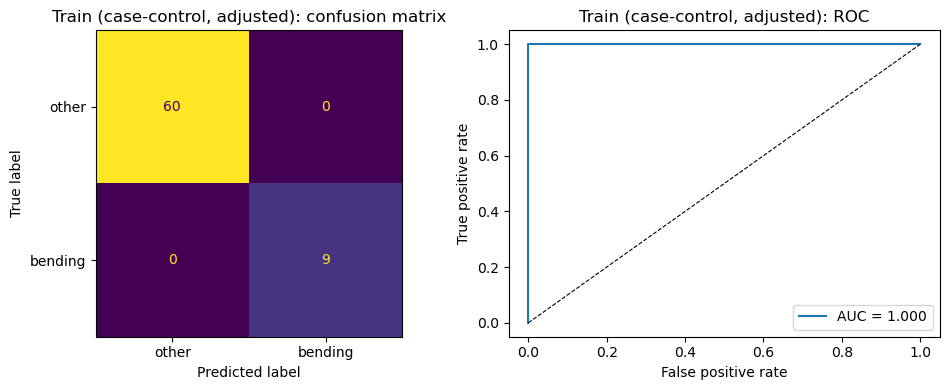

Train (case-control, adjusted): accuracy = 1.0000, AUC = 1.0000


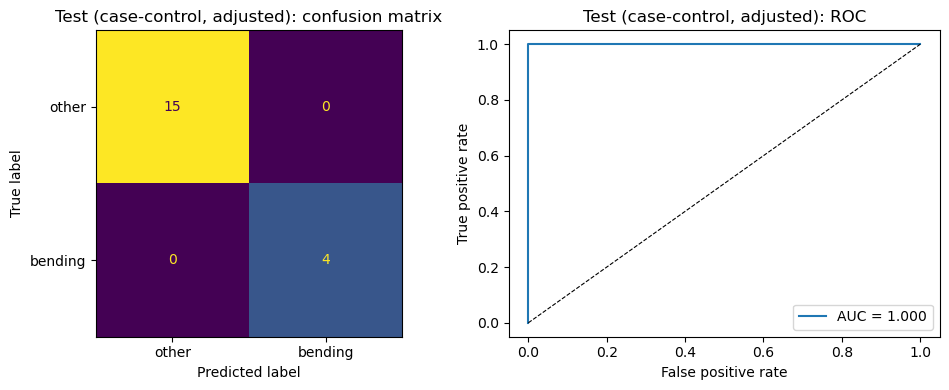

Test (case-control, adjusted): accuracy = 1.0000, AUC = 1.0000


In [19]:
random_num_g = np.random.default_rng(SEED)
cases = np.where(ytrain == 1)[0]
controls = random_num_g.choice(np.where(ytrain == 0)[0], size=len(cases), replace=False)
cc = np.r_[cases, controls]

lr_cc = LR_UNPENALIZED().fit(Ztrain[cc][:, selected_idx], ytrain[cc])
pi, pi_tilde = ytrain.mean(), ytrain[cc].mean()
b0_adj = lr_cc.intercept_[0] + np.log(pi / (1 - pi)) - np.log(pi_tilde / (1 - pi_tilde))
print(f'pi = {pi:.4f}, pi_tilde = {pi_tilde:.2f}')
print(f'intercept before = {lr_cc.intercept_[0]:.4f}, after adjustment = {b0_adj:.4f}')
print('slopes:', dict(zip(selected_names, lr_cc.coef_.ravel().round(4))))

def cc_prob(Z):
    eta = b0_adj + Z[:, selected_idx] @ lr_cc.coef_.ravel()
    return 1 / (1 + np.exp(-eta))

show_confusion_matrix_roc(ytrain, cc_prob(Ztrain), 'Train (case-control, adjusted)')
show_confusion_matrix_roc(ytest, cc_prob(Ztest), 'Test (case-control, adjusted)');

From our results we see that the case-control model and the full models had similar slopes. When we evaluate the case-control model on training and test sets it gets every instance right. This is because bending and other boundary is already pretty clean so balancing won't affect this result. The interception correction also will never have an effect on the AUC as it only changes predicted probabilities.

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [20]:
C_GRID = np.logspace(-2, 3, 21)
rows, best_models = [], {}
for l in range(1, 21):
    X_feats_l, env = extract_features(train_inst, l)
    y = is_bending(env)
    pipe = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000))
    grid_search = GridSearchCV(pipe, {'logisticregression__C': C_GRID}, cv=cv, scoring='accuracy').fit(X_feats_l, y)
    res = pd.DataFrame(grid_search.cv_results_)
    for C, s in zip(res['param_logisticregression__C'], res['mean_test_score']):
        rows.append(dict(l=l, C=C, cv_acc=s))

cv_l1 = pd.DataFrame(rows)
best = cv_l1.sort_values(['cv_acc', 'l', 'C'], ascending=[False, True, True]).iloc[0]
L_L1, C_L1, CV_ACC_L1 = int(best.l), best.C, best.cv_acc
print(cv_l1.sort_values(['cv_acc', 'l', 'C'], ascending=[False, True, True]).head(10).to_string(index=False))
print(f'\nBest: l = {L_L1}, C = {C_L1:.4g}, CV accuracy = {CV_ACC_L1:.4f}')

 l          C   cv_acc
 1  17.782794 0.985714
 1  31.622777 0.985714
 1  56.234133 0.985714
 1 100.000000 0.985714
 1 177.827941 0.985714
 1 316.227766 0.985714
 1   0.562341 0.980952
 1   5.623413 0.980952
 1  10.000000 0.980952
 1   1.000000 0.976190

Best: l = 1, C = 17.78, CV accuracy = 0.9857


8 of 18 coefficients are non-zero:
mean1   -1.2199
max2    -0.7902
min3    -0.2454
mean3   -1.6392
min5     3.6055
mean5    0.3371
max5     4.7995
mean6   -0.4533


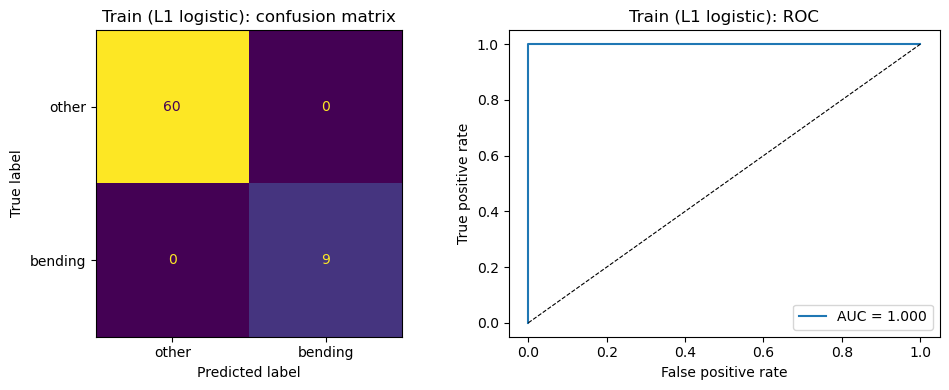

Train (L1 logistic): accuracy = 1.0000, AUC = 1.0000


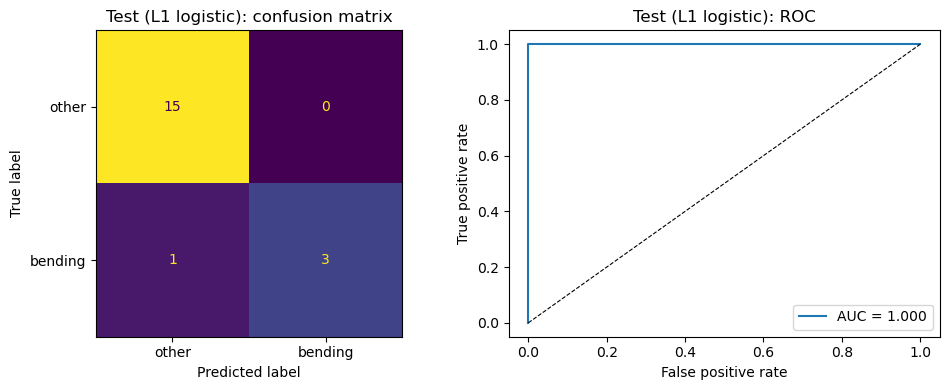

Test (L1 logistic): accuracy = 0.9474, AUC = 1.0000


In [21]:
Xtrain_df, env_train = extract_features(train_inst, L_L1)
Xtest_df, env_test = extract_features(test_inst, L_L1)
ytr1, yte1 = is_bending(env_train), is_bending(env_test)
l1_model = make_pipeline(StandardScaler(),
                         LogisticRegression(penalty='l1', solver='liblinear', C=C_L1, max_iter=1000)).fit(Xtrain_df, ytr1)
coefs = pd.Series(l1_model[-1].coef_.ravel(), index=Xtrain_df.columns)
print(f'{(coefs != 0).sum()} of {len(coefs)} coefficients are non-zero:')
print(coefs[coefs != 0].round(4).to_string())

show_confusion_matrix_roc(ytr1, l1_model.predict_proba(Xtrain_df)[:, 1], 'Train (L1 logistic)')
TEST_ACC_L1, TEST_AUC_L1 = show_confusion_matrix_roc(yte1, l1_model.predict_proba(Xtest_df)[:, 1], 'Test (L1 logistic)')

#### ii. Comparison

In [22]:
pd.DataFrame({'RFE (backward selection)': [f'l={L_BEST}, p={P_BEST}', CV_ACC_REC_FEAT_ELIM, TEST_ACC_RFE, TEST_AUC_RFE],
              'L1-penalized': [f'l={L_L1}, C={C_L1:.3g}', CV_ACC_L1, TEST_ACC_L1, TEST_AUC_L1]},
             index=['chosen by CV', 'CV accuracy', 'test accuracy', 'test AUC'])

,RFE (backward selection),L1-penalized
chosen by CV,"l=1, p=10","l=1, C=17.8"
CV accuracy,0.990476,0.985714
test accuracy,1.0,0.947368
test AUC,1.0,1.0


When it comes to performance we see that both of their CV accuracies are essentially the same. So they rank about the same in terms of performance. Now L1 is way easier to implement that RFE because its just one model with one tuning parameter. Selection also takes place automiaticaly we see that he p-valeu route breaks outirght on our data somethign we don't see in the RFE. Overall the L1 model is just much more friendly when it comes to implementing.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [23]:
cv_multiclass = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
C_GRID_M = np.logspace(-1, 3, 9)
rows = []
for l in range(1, 21):
    Xl, y = extract_features(train_inst, l)
    pipe = make_pipeline(StandardScaler(),
                         LogisticRegression(penalty='l1', solver='saga', max_iter=3000, tol=1e-3))
    gs = GridSearchCV(pipe, {'logisticregression__C': C_GRID_M}, cv=cv_multiclass, scoring='accuracy', n_jobs=-1).fit(Xl, y)
    res = pd.DataFrame(gs.cv_results_)
    rows += [dict(l=l, C=C, cv_acc=s) for C, s in zip(res['param_logisticregression__C'], res['mean_test_score'])]

cv_mn = pd.DataFrame(rows)
best = cv_mn.sort_values(['cv_acc', 'l', 'C'], ascending=[False, True, True]).iloc[0]
L_BEST, C_BEST, CV_ACC_BEST = int(best.l), best.C, best.cv_acc
print(cv_mn.sort_values(['cv_acc', 'l', 'C'], ascending=[False, True, True]).head(8).to_string(index=False))
print(f'\nBest: l = {L_BEST}, C = {C_BEST:.4g}, CV accuracy = {CV_ACC_BEST:.4f}')

 l           C   cv_acc
 2   31.622777 0.914286
 1   10.000000 0.913187
 1 1000.000000 0.913187
 1   31.622777 0.898901
 1  100.000000 0.898901
 1  316.227766 0.898901
 1    3.162278 0.897802
 1    1.000000 0.884615

Best: l = 2, C = 31.62, CV accuracy = 0.9143


We actually see a different choice when compared to 2b(i). here l = 2 and C = 31.62 were selected as the best options. Although to be fair l = 2 barely won by the thinnest margins.

non-zero coefficients: 190 of 252


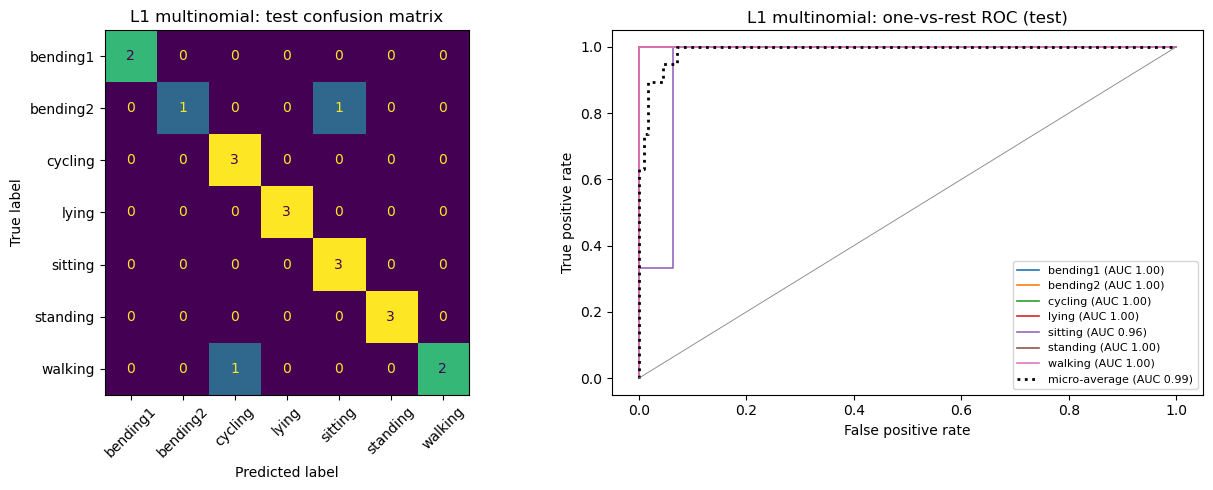

L1 multinomial: test error = 0.1053 (2 of 19 wrong), macro AUC = 0.9940, micro AUC = 0.9903


In [24]:
def multiclass_summary(model, Xte, yte, title):
    prediction = model.predict(Xte)
    probability = model.predict_proba(Xte)
    classes = model.classes_
    fig, ax = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay(confusion_matrix(yte, prediction, labels=classes), display_labels=classes).plot(
        ax=ax[0], colorbar=False, xticks_rotation=45)
    ax[0].set_title(f'{title}: test confusion matrix')
    Y = label_binarize(yte, classes=classes)
    for k, c in enumerate(classes):
        fpr, tpr, _ = roc_curve(Y[:, k], probability[:, k])
        ax[1].plot(fpr, tpr, lw=1.2, label=f'{c} (AUC {auc(fpr, tpr):.2f})')
    fpr, tpr, _ = roc_curve(Y.ravel(), probability.ravel())
    micro = auc(fpr, tpr)
    ax[1].plot(fpr, tpr, 'k:', lw=2, label=f'micro-average (AUC {micro:.2f})')
    ax[1].plot([0, 1], [0, 1], color='grey', lw=.6)
    ax[1].set(xlabel='False positive rate', ylabel='True positive rate', title=f'{title}: one-vs-rest ROC (test)')
    ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
    err = 1 - accuracy_score(yte, prediction)
    macro = roc_auc_score(yte, probability, multi_class='ovr', average='macro', labels=classes)
    print(f'{title}: test error = {err:.4f} ({(prediction != yte).sum()} of {len(yte)} wrong), '
          f'macro AUC = {macro:.4f}, micro AUC = {micro:.4f}')
    return err

Xtrain_df, ytr_m = extract_features(train_inst, L_BEST)
Xtest_df, yte_m = extract_features(test_inst, L_BEST)
mn_model = make_pipeline(StandardScaler(), LogisticRegression(penalty='l1', solver='saga', C=C_BEST,
                                                              max_iter=3000, tol=1e-3)).fit(Xtrain_df, ytr_m)
print(f'non-zero coefficients: {(mn_model[-1].coef_ != 0).sum()} of {mn_model[-1].coef_.size}')
ERR_BEST = multiclass_summary(mn_model, Xtest_df, yte_m, 'L1 multinomial')

This is a multiclass confusion matrix which means the diagonal has the correct predictions. Because ROC curves are made for two classes we have to go with the one vs rest strategy. So for every class we'll treat just that one as positive and the rest negative and get the ROC from the predicted probability. We can then get the macro 

#### ii. Naive Bayes

In [32]:
rows = []
for l in range(1, 21):
    X_feat_l, y = extract_features(train_inst, l)
    g = cross_val_score(GaussianNB(), X_feat_l, y, cv=cv_multiclass, scoring='accuracy').mean()
    gs = GridSearchCV(make_pipeline(MinMaxScaler(), MultinomialNB()),
                      {'multinomialnb__alpha': [0.01, 0.1, 0.5, 1.0]}, cv=cv_multiclass, scoring='accuracy').fit(X_feat_l, y)
    rows.append(dict(l=l, gaussian_cv=g, multinomial_cv=gs.best_score_, multinomial_alpha=gs.best_params_['multinomialnb__alpha']))
convo_nb = pd.DataFrame(rows)

L_Gaussian = int(convo_nb.sort_values(['gaussian_cv', 'l'], ascending=[False, True]).iloc[0].l)
bm = convo_nb.sort_values(['multinomial_cv', 'l'], ascending=[False, True]).iloc[0]
L_Multinomial, ALPHA_Multinomial = int(bm.l), bm.multinomial_alpha
CV_Gaussian = convo_nb.set_index('l').loc[L_Gaussian, 'gaussian_cv']; CV_Multinomial = bm.multinomial_cv
print(convo_nb.round(4).to_string(index=False))
print(f'\nGaussian NB: best l = {L_Gaussian} (CV acc {CV_Gaussian:.4f});  Multinomial NB: best l = {L_Multinomial}, alpha = {ALPHA_Multinomial} (CV acc {CV_Multinomial:.4f})')

 l  gaussian_cv  multinomial_cv  multinomial_alpha
 1       0.8989          0.6670               0.01
 2       0.8846          0.6505               0.01
 3       0.7956          0.6791               0.50
 4       0.7967          0.7099               0.10
 5       0.7824          0.7385               0.01
 6       0.7231          0.7374               0.10
 7       0.7516          0.7242               1.00
 8       0.7077          0.7352               0.01
 9       0.7231          0.7495               0.01
10       0.7099          0.7945               0.10
11       0.6802          0.8099               0.01
12       0.6374          0.7670               0.10
13       0.6538          0.7802               0.01
14       0.6231          0.7516               0.01
15       0.5956          0.7516               0.10
16       0.6077          0.7802               0.10
17       0.6088          0.7813               0.01
18       0.5659          0.7824               0.01
19       0.5813          0.7813

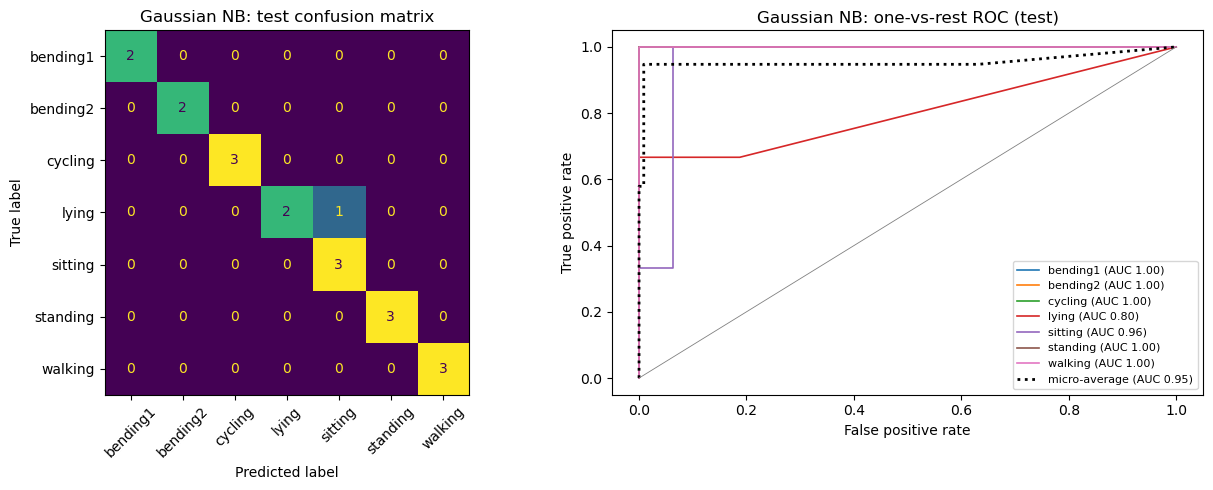

Gaussian NB: test error = 0.0526 (1 of 19 wrong), macro AUC = 0.9658, micro AUC = 0.9538


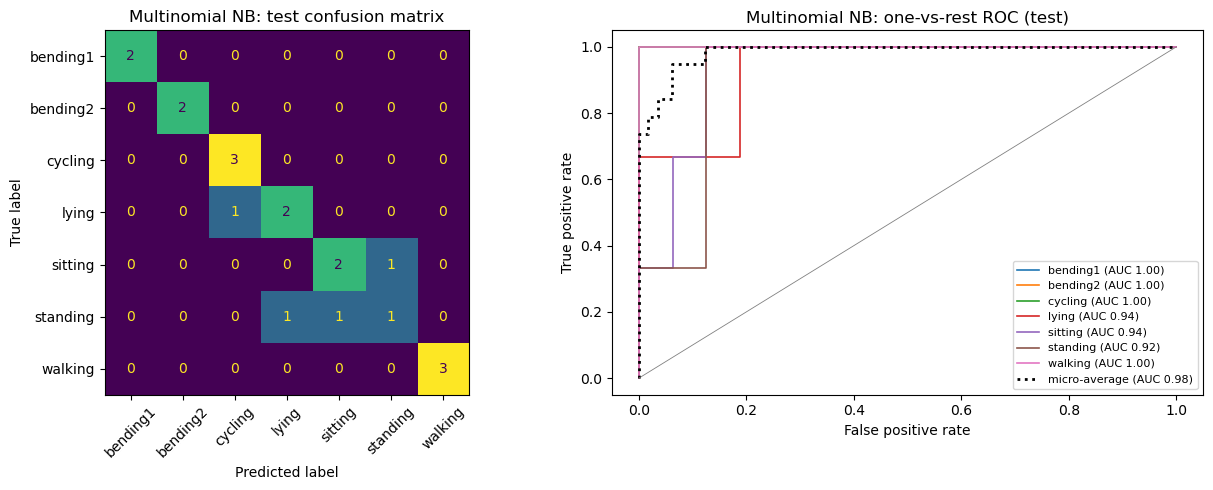

Multinomial NB: test error = 0.2105 (4 of 19 wrong), macro AUC = 0.9702, micro AUC = 0.9843


In [33]:
Xtrain_df, ytrain_g = extract_features(train_inst, L_Gaussian); Xte_df, yte_g = extract_features(test_inst, L_Gaussian)
ERR_Gaussian = multiclass_summary(GaussianNB().fit(Xtrain_df, ytrain_g), Xte_df, yte_g, 'Gaussian NB')

Xtr_df, ytr_mm = extract_features(train_inst, L_Multinomial); Xte_df, yte_mm = extract_features(test_inst, L_Multinomial)
mnb = make_pipeline(MinMaxScaler(), MultinomialNB(alpha=ALPHA_Multinomial)).fit(Xtr_df, ytr_mm)
ERR_Multinomial = multiclass_summary(mnb, Xte_df, yte_mm, 'Multinomial NB')

#### iii. Comparison

In [34]:
pd.DataFrame({'l': [L_BEST, L_Gaussian, L_Multinomial], 'CV accuracy': [CV_ACC_REC_FEAT_ELIM, CV_Gaussian, CV_Multinomial], 'test error': [ERR_BEST, ERR_Gaussian, ERR_Multinomial]},
             index=['L1 multinomial logistic', 'Gaussian NB', 'Multinomial NB']).round(4)

,l,CV accuracy,test error
L1 multinomial logistic,2,0.9905,0.1053
Gaussian NB,1,0.8989,0.0526
Multinomial NB,11,0.8099,0.2105


We see that the L1-penalized multinomial logistic regression is the best method we have, it only got 1 of 19 instances wrong.. We see it has the best cv accuracy at 0.9905. Then its Gaussian Method second best and finally multinomial. Gaussian is second because it assumes the features are indpendent within each class which we know is false. Multinomial did even worse because its great at modeling count data and in thsi case our min/mean/max readings are not counts. One thign we do sea cross all models is that they struggel when it comes to distinguishing between lying, sitting, and standing.

## 3. ISLR 4.8.3



So we want to be able to prove that The Bayes classifier assigns $x$ to the class with the largest posterior

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^K \pi_l f_l(x)}, \qquad
f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\!\left(-\frac{(x-\mu_k)^2}{2\sigma_k^2}\right).$$

Here we see that the denominator is the same for every $k$, and $\log$ is increasing, so that means if we maximize $p_k(x)$ then that's same as
maximizing $\log\big(\pi_k f_k(x)\big)$:

$$\log\big(\pi_k f_k(x)\big) = \log\pi_k - \tfrac12\log(2\pi) - \log\sigma_k - \frac{(x-\mu_k)^2}{2\sigma_k^2}.$$

Firstly we drop this constant $-\tfrac12\log(2\pi)$ because all classes share it and then we expand the square:

$$\delta_k(x) = -\frac{x^2}{2\sigma_k^2} + \frac{\mu_k}{\sigma_k^2}\,x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k.$$

We can go ahead and get rid of the $-x^2/(2\sigma^2)$ term because its the same across all classes and it will cancel out when comparing them, this is true because its LDA and every class has the same $\sigma^2$. When we do this it leaves a linear in x dicriminant. Unlike $\sigma^2$,  $\sigma_k$ actually does differ by class, so the
coefficient $-1/(2\sigma_k^2)$ of $x^2$ differs too and we can't jsut cancel it out. The decision boundary between classes
$l$ and $k$, $\delta_k(x) = \delta_l(x)$, is therefore

$$\left(\frac{1}{2\sigma_l^2} - \frac{1}{2\sigma_k^2}\right)x^2 + \left(\frac{\mu_k}{\sigma_k^2} - \frac{\mu_l}{\sigma_l^2}\right)x
+ \left(\frac{\mu_l^2}{2\sigma_l^2} - \frac{\mu_k^2}{2\sigma_k^2} + \log\frac{\sigma_l}{\sigma_k} + \log\frac{\pi_k}{\pi_l}\right) = 0,$$

and we know this is a quadratic because $\sigma_k \neq \sigma_l$



## 4. ISLR 4.8.7


So we know $\bar X_{\text{no}} = 0$,  $\bar X_{\text{yes}} = 10$, common $\hat\sigma^2 = 36$, and 80% of companies issued
dividends, so this automaticaly also gives us these otehr two porabilities we'll need: $\pi_{\text{no}} = 0.2$, $\pi_{\text{yes}} = 0.8$. When $X = 4$, our Bayes' theorem with normal densities will look like:
(this takes into acount that the $1/\sqrt{2\pi\sigma^2}$ factors cancel because the variance is shared)

$$P(\text{yes}\mid X=4) = \frac{0.8\, e^{-(4-10)^2/(2\cdot 36)}}{0.8\, e^{-(4-10)^2/(2\cdot 36)} + 0.2\, e^{-(4-0)^2/(2\cdot 36)}}
= \frac{0.8\, e^{-0.5}}{0.8\, e^{-0.5} + 0.2\, e^{-0.2222}}.$$

$0.8\,e^{-0.5} = 0.8 \times 0.60653 = 0.48522$ and $0.2\,e^{-0.2222} = 0.2 \times 0.80074 = 0.16015$, so

$$P(\text{yes}\mid X=4) = \frac{0.48522}{0.48522 + 0.16015} = \frac{0.48522}{0.64537} \approx \mathbf{0.752}.$$

So we get about a **75.2%** chance the company issues a dividend this year.

## 5.1. Extra Practice ISLR 4.8.4

## 5.2. Extra Practice ISLR 4.8.9